# Configurable Abu Dhabi autonomy planning

This notebook sizes discrete solar and battery equipment for a configurable islanded period. The default planning question is:

`P(total unmet energy during a 24-hour horizon > 0.1 kWh) <= 5%`

The default site is Abu Dhabi city centre (`24.4539, 54.3773`, `Asia/Dubai`). Every episode starts from the configured battery state of charge; there is no controller or state-of-charge burn-in. Training, validation, and final-test simulations use independent seeds and manifests.


## What the result means

This is an autonomy-planning study, not an absolute blackout guarantee. A recommendation is released only if held-out calibration, native-SPFlow/MIO parity, and a one-sided held-out 95% risk bound all pass. Otherwise the HiGHS result is still shown, but it is labeled **exploratory**.

PVGIS TMY describes typical meteorology rather than interannual extremes. The default synthetic small-commercial demand is illustrative and not calibrated to an Abu Dhabi site. A decision-grade run needs aligned measured site demand.


## How the notebook is organized

The workflow is deliberately separated into stages so that assumptions, generated evidence, and decision gates remain distinct:

1. Configure the location, physical system, uncertainty, equipment grid, and statistical thresholds.
2. Load one canonical PVGIS TMY and fit weather and demand artifacts.
3. Build the simulator template and generate independent train, validation, and test datasets.
4. Fit and select SPFlow candidates using validation evidence only.
5. Solve the compiled planning problem with HiGHS.
6. Use the untouched final-test split to decide whether the result can be recommended.

Matplotlib and Seaborn are used for figures. They are isolated in the `notebook` dependency group and are not imported by the core library.


## 0. Imports and plotting setup

Imports are grouped by responsibility. The only local plotting helper below saves a normal Matplotlib figure; chart construction stays visible in the cells where the data is interpreted.


In [1]:
from dataclasses import asdict
from pathlib import Path

# Notebook-only analysis and visualization dependencies.
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# Demand fitting and input preparation.
from open_energy_lab.demand import (
    SyntheticCommercialDemandConfig,
    build_measured_demand_training_payload,
    build_synthetic_demand_training_payload,
    fit_demand_model,
)

# Planning study, model selection, solve, and validation surfaces.
from open_energy_lab.planning import (
    AdequacyEventDefinition,
    BatteryDesignOption,
    GridAvailabilityPolicy,
    PlanningStudyRequest,
    SPNCandidateScore,
    SolarDesignOption,
    assess_calibration,
    assess_recommendation,
    brier_score_by_configuration,
    compile_planning_study_tpm,
    fit_planning_study_tpm,
    iter_study_rows,
    select_spn_candidate,
    solve_planning_study,
)

# Simulator components used to create a reusable scenario template.
from open_energy_lab.simulator import (
    ArbitrageObjectiveRepresentation,
    BatteryComponent,
    BatteryLoadPVScenario,
    DispatchRequestSeries,
    LoadComponent,
    PVComponent,
    PriceSignal,
    generate_planning_study_dataset,
)
from open_energy_lab.simulator.demand import (
    CoolingServiceConfiguration,
    LocalElectricCoolingConfiguration,
)
from open_energy_lab.simulator.weather import weather_component_from_sampled_trace

# SPFlow fitting/query and weather artifact APIs remain lazy in the library.
from open_energy_lab.tpm import TPMFitConfig, TPMQueryRequest, query_tpm_artifact
from open_energy_lab.weather import (
    PVGISTMYRequestConfig,
    WeatherSamplingRequest,
    fit_weather_dataset,
    load_or_fetch_tmy_dataset,
    load_weather_artifact,
    sample_weather_family,
)


In [2]:
# Use one consistent, accessible visual style throughout the notebook.
sns.set_theme(context="notebook", style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160})

VISUALIZATION_ROOT = Path.cwd() / "tmp/abu-dhabi-autonomy-study/visualizations"
VISUALIZATION_ROOT.mkdir(parents=True, exist_ok=True)

def save_figure(fig, filename):
    """Save a Matplotlib figure and return its reproducible output path."""
    output_path = VISUALIZATION_ROOT / filename
    fig.savefig(output_path, bbox_inches="tight")
    print("Saved", output_path)
    return output_path


## 1. Study configuration

Configuration is split into three cells: external data and paths, physical assumptions, and planning evidence. This makes it easier to change one concern without accidentally changing another.


### 1.1 Paths, site, and weather source

The canonical weather table and all generated artifacts stay under `tmp/`. The PVGIS endpoint is deliberately versioned to 5.3. A missing cache plus unavailable or disabled network access is a hard error; no fixture is silently substituted.


In [3]:
REPO_ROOT = Path.cwd()
OUTPUT_ROOT = REPO_ROOT / "tmp/abu-dhabi-autonomy-study"
CACHE_ROOT = OUTPUT_ROOT / "cache"

LOCATION = {
    "name": "Abu Dhabi city centre",
    "latitude": 24.4539,
    "longitude": 54.3773,
    "timezone": "Asia/Dubai",
}

WEATHER_API = PVGISTMYRequestConfig(
    endpoint_url="https://re.jrc.ec.europa.eu/api/v5_3/",
    use_horizon=True,
    start_year=None,
    end_year=None,
    timeout_seconds=30,
)
ALLOW_NETWORK = True
REFRESH_WEATHER_CACHE = False


### 1.2 Autonomy horizon, battery state, and demand source

`LOCAL_START_STEP` is the local civil hour at which every autonomy episode begins. The battery is reset to `INITIAL_SOC` at that point; earlier sampled weather is not used as battery burn-in.


In [4]:
HORIZON_STEPS = 24
LOCAL_START_STEP = 0
TIMESTEP_HOURS = 1.0

INITIAL_SOC = 1.0
MINIMUM_SOC = 0.10
CHARGE_EFFICIENCY = 0.95
DISCHARGE_EFFICIENCY = 0.95

DEMAND_MODE = "synthetic"  # Choose "synthetic" or "measured_csv".
MEASURED_DEMAND_CSV = REPO_ROOT / "data/abu_dhabi_measured_demand.csv"
SYNTHETIC_DEMAND = SyntheticCommercialDemandConfig(
    random_seed=20260820,
    electric_kw_per_rt=1.15,
)


### 1.3 Equipment catalog, event definition, and evidence budget

The first-release planning decision is battery and solar sizing only. Costs are illustrative AED capital costs. Train, validation, and final-test seeds are intentionally different so model selection cannot reuse final evidence.


In [5]:
SOLAR_CAPACITIES_KW = (80.0, 120.0, 160.0)
BATTERY_CAPACITIES_KWH = (100.0, 200.0, 300.0)
BATTERY_C_RATE = 0.5

SOLAR_COST_AED_PER_KW = 3_000.0
BATTERY_COST_AED_PER_KWH = 1_200.0

GRID_MODE = "islanded"  # Choose "islanded" or "markov".
MARKOV_OUTAGE_START_PROBABILITY = 0.02
MARKOV_RECOVERY_PROBABILITY = 0.30

EVENT_KIND = "unmet_energy_kwh"
EVENT_THRESHOLD = 0.1
CHANCE_LIMIT = 0.05

SAMPLE_COUNTS = {"train": 1_000, "validation": 250, "test": 250}
SPLIT_SEEDS = {"train": 13, "validation": 37, "test": 101}
BATCH_SIZE = 100
WORKER_COUNT = 1
SHARD_FORMAT = "parquet"

SPN_CANDIDATES = {
    "default": {},
    "finer": {"min_instances_slice": 100, "threshold": 0.15},
    "coarser": {"min_instances_slice": 1_000, "threshold": 0.50},
}

MEAN_CALIBRATION_ERROR_LIMIT = 0.05
MAX_CALIBRATION_ERROR_LIMIT = 0.10
NATIVE_MIO_TOLERANCE = 1e-6
MAX_TENSOR_BYTES = 512 * 1024 * 1024


## 2. Load the canonical PVGIS TMY and fit weather once

The canonical hourly table and fitted weather artifact are separate cached products. `fit_weather_dataset` consumes the already fetched table, so a fresh run performs at most one live request. PVGIS 5.3 is used because that API generation includes relevant TMY timestamp corrections for regions including the Middle East.

References: [PVGIS API documentation](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system/pvgis/using-pvgis-5/api-non-interactive-service_en) and [TMY documentation](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system/pvgis/using-pvgis-5/pvgis-5-tools/pvgis-typical-meteorological-year-tmy-generator_en).


In [6]:
canonical_weather_path = CACHE_ROOT / "abu-dhabi-pvgis-5.3-tmy-canonical.json"
weather_artifact_path = CACHE_ROOT / "abu-dhabi-pvgis-5.3-weather-artifact.json"

# Load a request-compatible cache or make exactly one configured live request.
canonical_weather = load_or_fetch_tmy_dataset(
    LOCATION["latitude"],
    LOCATION["longitude"],
    timezone_name=LOCATION["timezone"],
    cache_path=canonical_weather_path,
    api_config=WEATHER_API,
    allow_network=ALLOW_NETWORK,
    refresh_cache=REFRESH_WEATHER_CACHE,
)

record_count = len(canonical_weather.timestamp_utc)
if record_count != 8_760:
    raise ValueError(
        f"expected one 8,760-record hourly TMY; received {record_count:,}"
    )


In [7]:
# Reuse the fitted artifact only when it was built from this canonical dataset.
artifact_matches_dataset = False
if weather_artifact_path.exists():
    weather_artifact = load_weather_artifact(
        weather_artifact_path,
        expected_timestep_hours=TIMESTEP_HOURS,
    )
    artifact_matches_dataset = (
        weather_artifact.training_record_summary["dataset_id"]
        == canonical_weather.dataset_id
    )

if not artifact_matches_dataset:
    weather_artifact = fit_weather_dataset(
        canonical_weather,
        output_path=weather_artifact_path,
    )

weather_provenance = {
    "canonical_records": record_count,
    "canonical_cache": canonical_weather.source_metadata["cache_provenance"],
    "weather_artifact": weather_artifact_path,
    "pvgis_request": canonical_weather.source_metadata.get(
        "pvgis_request", WEATHER_API.to_dict()
    ),
}
display(pd.Series(weather_provenance, name="weather provenance"))


canonical_records                                                 8760
canonical_cache      {'status': 'hit', 'path': '/home/nicolas.avila...
weather_artifact     /home/nicolas.avila/dev/open-energy-lab/tmp/ab...
pvgis_request        {'end_year': None, 'endpoint_url': 'https://re...
Name: weather provenance, dtype: object

### 2.1 Inspect representative days and hourly irradiance uncertainty

The first panel compares the coldest, median, and hottest TMY days by daily mean temperature. The second panel shows the 10th–90th percentile GHI envelope by local hour. These plots describe the TMY sample; they do not establish interannual extremes.


In [8]:
# Convert canonical field arrays into a labeled analysis table.
weather_frame = pd.DataFrame(
    {
        name: canonical_weather.field_series[name]
        for name in canonical_weather.canonical_field_order[1:]
    }
)
weather_frame["local_timestamp"] = pd.to_datetime(
    canonical_weather.local_civil_step_labels
)
weather_frame["local_date"] = weather_frame["local_timestamp"].dt.date
weather_frame["local_hour"] = weather_frame["local_timestamp"].dt.hour

# Select representative dates using daily mean dry-bulb temperature.
daily_temperature = (
    weather_frame.groupby("local_date")["dry_bulb_air_temperature_c"]
    .mean()
    .sort_values()
)
representative_dates = [
    daily_temperature.index[0],
    daily_temperature.index[len(daily_temperature) // 2],
    daily_temperature.index[-1],
]

# Summarize the distribution of GHI at each local civil hour.
hourly_ghi = (
    weather_frame.groupby("local_hour")["global_horizontal_irradiance_w_per_m2"]
    .quantile([0.1, 0.5, 0.9])
    .unstack()
)


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/weather-overview.svg


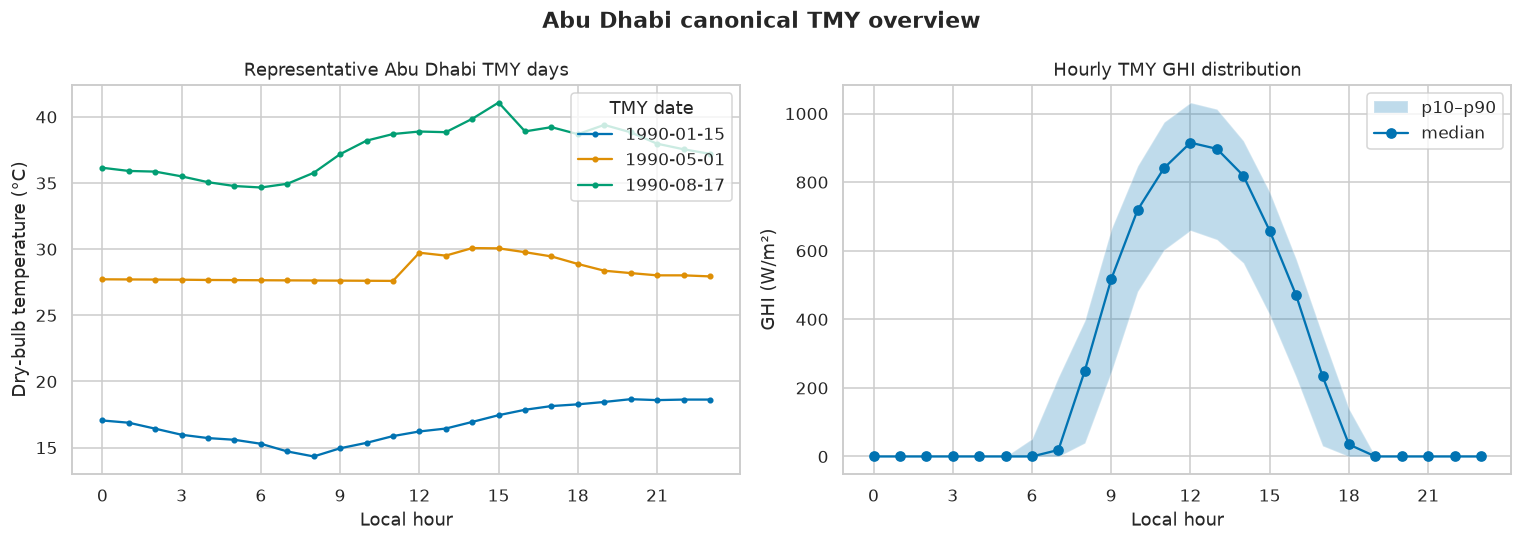

In [9]:
fig, (temperature_ax, ghi_ax) = plt.subplots(1, 2, figsize=(14, 5))

for date in representative_dates:
    day = weather_frame.loc[weather_frame["local_date"] == date]
    temperature_ax.plot(
        day["local_hour"],
        day["dry_bulb_air_temperature_c"],
        marker="o",
        markersize=3,
        label=str(date),
    )

temperature_ax.set(
    title="Representative Abu Dhabi TMY days",
    xlabel="Local hour",
    ylabel="Dry-bulb temperature (°C)",
    xticks=range(0, 24, 3),
)
temperature_ax.legend(title="TMY date")

ghi_ax.fill_between(
    hourly_ghi.index,
    hourly_ghi[0.1],
    hourly_ghi[0.9],
    alpha=0.25,
    label="p10–p90",
)
ghi_ax.plot(hourly_ghi.index, hourly_ghi[0.5], marker="o", label="median")
ghi_ax.set(
    title="Hourly TMY GHI distribution",
    xlabel="Local hour",
    ylabel="GHI (W/m²)",
    xticks=range(0, 24, 3),
)
ghi_ax.legend()

fig.suptitle("Abu Dhabi canonical TMY overview", fontweight="bold")
fig.tight_layout()
save_figure(fig, "weather-overview.svg")
plt.show()


## 3. Prepare and fit demand

`synthetic` generates a labeled, reproducible small-commercial history from the TMY: roughly 12–30 kW non-cooling baseline, occupancy/temperature/humidity cooling, and correlated Gaussian residuals. `measured_csv` requires at least 90 complete hourly days and separate non-cooling electricity and cooling RT columns. Total electricity without separate cooling is rejected to prevent double counting.

Both modes pass through the same `fit_demand_model` workflow. The source choice changes evidence provenance, not the downstream simulator interface.


In [10]:
if DEMAND_MODE == "synthetic":
    demand_training_payload = build_synthetic_demand_training_payload(
        canonical_weather,
        config=SYNTHETIC_DEMAND,
    )
elif DEMAND_MODE == "measured_csv":
    demand_training_payload = build_measured_demand_training_payload(
        MEASURED_DEMAND_CSV,
        timezone_name=LOCATION["timezone"],
    )
else:
    raise ValueError("DEMAND_MODE must be 'synthetic' or 'measured_csv'")

# Convert cooling demand locally using the configured 1.15 kW/RT assumption.
non_cooling_kw = pd.Series(
    demand_training_payload["non_thermal_electric_demand_kw"]
)
cooling_rt = pd.Series(demand_training_payload["cooling_demand_rt"])
training_total_kw = non_cooling_kw + SYNTHETIC_DEMAND.electric_kw_per_rt * cooling_rt


In [11]:
demand_artifact_path = CACHE_ROOT / f"demand-{DEMAND_MODE}-artifact.json"
demand_artifact_path.parent.mkdir(parents=True, exist_ok=True)

demand_artifact = fit_demand_model(
    demand_training_payload,
    output_path=demand_artifact_path,
)

demand_provenance = {
    "mode": DEMAND_MODE,
    "training peak kW": float(training_total_kw.max()),
    "artifact": demand_artifact_path,
    "source provenance": demand_training_payload["provenance"],
}
display(pd.Series(demand_provenance, name="demand provenance"))


mode                                                         synthetic
training peak kW                                             68.938052
artifact             /home/nicolas.avila/dev/open-energy-lab/tmp/ab...
source provenance    {'demand_source_mode': 'synthetic', 'profile_l...
Name: demand provenance, dtype: object

### 3.1 Compare the fitted mean with the input history

The fitted line is the deterministic hourly baseline plus fitted weather-response terms. Residual uncertainty is intentionally not drawn here; this chart checks whether the mean structure tracks the generated or measured training signal.


In [12]:
required_weather = demand_artifact.required_weather_field_order

def fitted_component_value(model, baseline_name, row_index):
    """Evaluate one fitted demand component at a training row."""
    local_timestamp = pd.Timestamp(
        demand_training_payload["local_civil_step_labels"][row_index]
    )
    fitted_value = float(model[baseline_name][local_timestamp.hour])

    for weather_name in required_weather:
        coefficient = float(model["weather_response_terms"][weather_name])
        weather_value = float(
            demand_training_payload["weather_field_series"][weather_name][row_index]
        )
        fitted_value += coefficient * weather_value

    return max(0.0, fitted_value)

plot_steps = min(7 * 24, len(training_total_kw))
fitted_total_kw = []

for row_index in range(plot_steps):
    fitted_non_cooling_kw = fitted_component_value(
        demand_artifact.non_thermal_electric_model,
        "local_step_baseline_kw",
        row_index,
    )
    fitted_cooling_rt = fitted_component_value(
        demand_artifact.cooling_demand_model,
        "local_step_baseline_rt",
        row_index,
    )
    fitted_total_kw.append(
        fitted_non_cooling_kw
        + SYNTHETIC_DEMAND.electric_kw_per_rt * fitted_cooling_rt
    )


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/fitted-versus-input-demand.svg


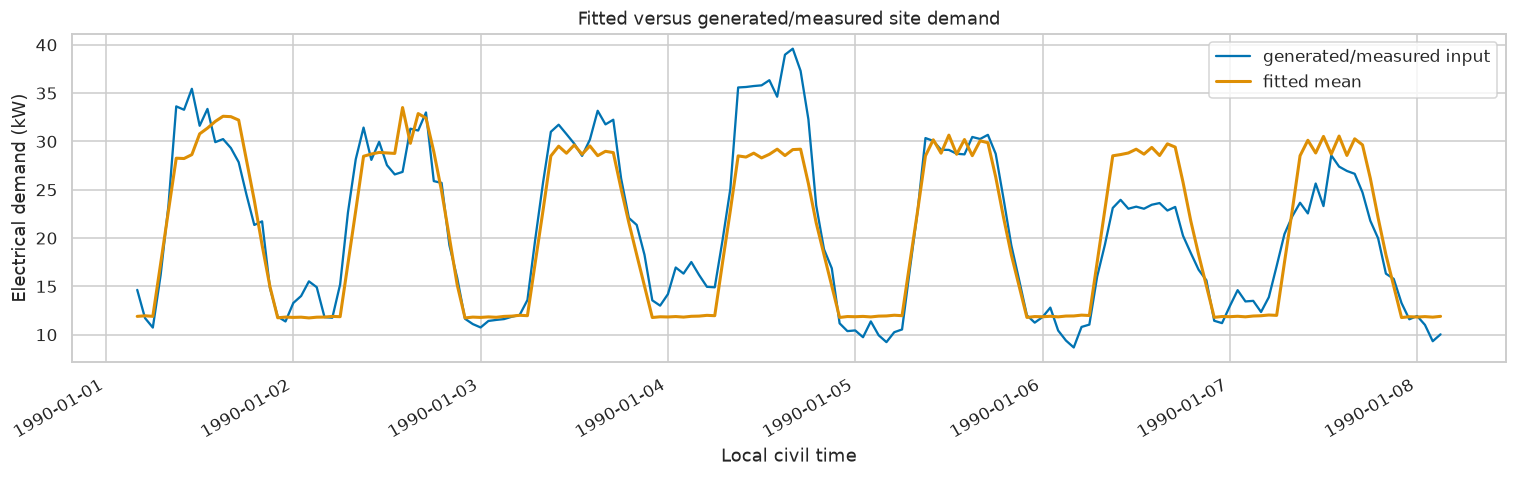

In [13]:
plot_timestamps = pd.to_datetime(
    demand_training_payload["local_civil_step_labels"][:plot_steps]
)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(
    plot_timestamps,
    training_total_kw.iloc[:plot_steps],
    label="generated/measured input",
    linewidth=1.5,
)
ax.plot(
    plot_timestamps,
    fitted_total_kw,
    label="fitted mean",
    linewidth=2,
)
ax.set(
    title="Fitted versus generated/measured site demand",
    xlabel="Local civil time",
    ylabel="Electrical demand (kW)",
)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
save_figure(fig, "fitted-versus-input-demand.svg")
plt.show()


## 4. Build the physical scenario and equipment grid

This section turns configuration values into explicit simulator components. Storage power is 0.5C. Every option sets 100% initial SOC, 10% minimum SOC, and 95% charge/discharge efficiency.

Each independently simulated episode starts at that SOC. Sampled history before `LOCAL_START_STEP` is used only to align weather and demand; it is not dispatched through the battery.


In [14]:
# Create one typed option for every battery capacity.
battery_options = tuple(
    BatteryDesignOption(
        option_id=f"battery-{capacity:g}",
        capacity_kwh=capacity,
        max_charge_kw=BATTERY_C_RATE * capacity,
        max_discharge_kw=BATTERY_C_RATE * capacity,
        installed_cost=BATTERY_COST_AED_PER_KWH * capacity,
        charge_efficiency=CHARGE_EFFICIENCY,
        discharge_efficiency=DISCHARGE_EFFICIENCY,
        initial_soc=INITIAL_SOC,
        min_soc=MINIMUM_SOC,
        max_soc=1.0,
    )
    for capacity in BATTERY_CAPACITIES_KWH
)

# Solar options contain rated power and installed cost.
solar_options = tuple(
    SolarDesignOption(
        option_id=f"solar-{capacity:g}",
        capacity_kw=capacity,
        installed_cost=SOLAR_COST_AED_PER_KW * capacity,
    )
    for capacity in SOLAR_CAPACITIES_KW
)

equipment_catalog = pd.DataFrame(
    [
        {"kind": "battery", **asdict(option)}
        for option in battery_options
    ]
    + [{"kind": "solar", **asdict(option)} for option in solar_options]
)
display(equipment_catalog)


,kind,option_id,capacity_kwh,max_charge_kw,max_discharge_kw,installed_cost,charge_efficiency,discharge_efficiency,initial_soc,min_soc,max_soc,capacity_kw,generation_cap_kw
0,battery,battery-100,100.0,50.0,50.0,120000.0,0.95,0.95,1.0,0.1,1.0,NaN,NaN
1,battery,battery-200,200.0,100.0,100.0,240000.0,0.95,0.95,1.0,0.1,1.0,NaN,NaN
2,battery,battery-300,300.0,150.0,150.0,360000.0,0.95,0.95,1.0,0.1,1.0,NaN,NaN
3,solar,solar-80,NaN,NaN,NaN,240000.0,NaN,NaN,NaN,NaN,NaN,80.0,NaN
4,solar,solar-120,NaN,NaN,NaN,360000.0,NaN,NaN,NaN,NaN,NaN,120.0,NaN
5,solar,solar-160,NaN,NaN,NaN,480000.0,NaN,NaN,NaN,NaN,NaN,160.0,NaN


In [15]:
# Sample one weather trace only to establish the aligned simulator time grid.
base_weather_family = sample_weather_family(
    weather_artifact,
    request=WeatherSamplingRequest(
        num_steps=HORIZON_STEPS,
        scenario_count=1,
        family_seed=SPLIT_SEEDS["train"],
        local_start_step=LOCAL_START_STEP,
    ),
    expected_timestep_hours=TIMESTEP_HOURS,
)
weather_component = weather_component_from_sampled_trace(
    base_weather_family.sampled_traces[0]
)
time_grid = weather_component.time_grid


In [16]:
# The planning-study generator replaces battery size, PV size, weather, and load
# for every configuration and sampled episode. Values here define the template.
battery_component = BatteryComponent(
    name="battery",
    capacity_kwh=BATTERY_CAPACITIES_KWH[0],
    max_charge_kw=BATTERY_C_RATE * BATTERY_CAPACITIES_KWH[0],
    max_discharge_kw=BATTERY_C_RATE * BATTERY_CAPACITIES_KWH[0],
    charge_efficiency=CHARGE_EFFICIENCY,
    discharge_efficiency=DISCHARGE_EFFICIENCY,
    initial_soc=INITIAL_SOC,
    min_soc=MINIMUM_SOC,
)

load_component = LoadComponent(
    name="placeholder-load",
    demand_kw=[0.0] * HORIZON_STEPS,
    interpretation="exogenous-consumption",
    time_grid=time_grid,
    source=f"{DEMAND_MODE}-demand-artifact",
)

pv_component = PVComponent(
    name="pv",
    rated_power_kw=SOLAR_CAPACITIES_KW[0],
    temperature_coefficient_pct_per_c=-0.4,
    reference_irradiance_w_per_m2=1_000.0,
    reference_temperature_c=25.0,
    derivation_name="ghi-linear-temperature-adjusted",
    irradiance_field_names=("global_horizontal_irradiance_w_per_m2",),
)


In [17]:
# Settlement is inactive in islanded operation, but PriceSignal still requires
# valid discounted-export metadata. Export remains explicitly disabled.
price_signal = PriceSignal(
    currency="AED",
    unit_rate_name="planning-placeholder",
    import_prices=[0.0] * HORIZON_STEPS,
    export_price_ratio=0.8,
    interpretation="discounted export placeholder; inactive for islanded planning",
    time_alignment="step-start",
    time_grid=time_grid,
)
objective = ArbitrageObjectiveRepresentation(
    objective_name="autonomy",
    settlement_basis="grid-settlement",
    allow_export=False,
    export_price_ratio=0.8,
)

base_scenario = BatteryLoadPVScenario(
    scenario_id="abu-dhabi-autonomy-template",
    time_grid=time_grid,
    battery=battery_component,
    load=load_component,
    weather=weather_component,
    pv=pv_component,
    price_signal=price_signal,
    objective=objective,
    dispatch_requests=DispatchRequestSeries(
        requested_power_kw=[0.0] * HORIZON_STEPS,
        sign_convention="charge",
        source="planning-controller",
    ),
)


In [18]:
# Cooling conversion remains simulator-side, separate from demand fitting.
cooling_configuration = CoolingServiceConfiguration(
    service_path="local-electric",
    local_electric_cooling=LocalElectricCoolingConfiguration(
        source_name="local-electric-cooling",
        electric_kw_per_rt=1.15,
        valid_for_feature_version="008-weather-demand-modeling",
        notes="Configured notebook conversion.",
    ),
    source="notebook-configuration",
)

event_definition = AdequacyEventDefinition(EVENT_KIND, EVENT_THRESHOLD)

if GRID_MODE == "islanded":
    grid_policy = GridAvailabilityPolicy(mode="islanded")
elif GRID_MODE == "markov":
    grid_policy = GridAvailabilityPolicy(
        mode="markov",
        initial_grid_available=True,
        outage_start_probability=MARKOV_OUTAGE_START_PROBABILITY,
        recovery_probability=MARKOV_RECOVERY_PROBABILITY,
    )
else:
    raise ValueError("GRID_MODE must be 'islanded' or 'markov'")


## 5. Generate independent train, validation, and final-test manifests

Within each split, the same absolute sample IDs are reused across all nine equipment configurations. This common-random-sample design makes configuration comparisons less noisy.

The three splits remain independent: training seed 13 fits SPFlow, validation seed 37 selects among candidates, and final-test seed 101 is reserved for calibration and recommendation gating. Default row counts are 9,000, 2,250, and 2,250 respectively.


In [19]:
study_requests = {}
manifests = {}
split_frames = {}

for split_name in ("train", "validation", "test"):
    request = PlanningStudyRequest(
        study_id=f"abu-dhabi-autonomy-{split_name}",
        battery_options=battery_options,
        solar_options=solar_options,
        samples_per_configuration=SAMPLE_COUNTS[split_name],
        horizon_steps=HORIZON_STEPS,
        local_start_step=LOCAL_START_STEP,
        batch_size=min(BATCH_SIZE, SAMPLE_COUNTS[split_name]),
        worker_count=WORKER_COUNT,
        random_seed=SPLIT_SEEDS[split_name],
        shard_format=SHARD_FORMAT,
        adequacy_event=event_definition,
        grid_availability=grid_policy,
    )

    # The request fingerprint keeps incompatible reruns in separate directories.
    manifest_root = (
        OUTPUT_ROOT
        / "datasets"
        / f"{split_name}-{request.request_fingerprint[:12]}"
    )
    manifest = generate_planning_study_dataset(
        request,
        weather_artifact=weather_artifact,
        demand_artifact=demand_artifact,
        base_scenario_reference=base_scenario,
        cooling_service_configuration=cooling_configuration,
        output_dir=manifest_root,
        expected_timestep_hours=TIMESTEP_HOURS,
    )

    study_requests[split_name] = request
    manifests[split_name] = manifest
    split_frames[split_name] = pd.DataFrame(tuple(iter_study_rows(manifest)))

    print(
        split_name,
        f"rows={manifest.row_count:,}",
        f"seed={SPLIT_SEEDS[split_name]}",
        f"sha={manifest.semantic_sha256[:16]}",
        manifest.source_path,
    )

# Fail early if the evidence budget is incomplete.
configuration_count = len(battery_options) * len(solar_options)
for split_name, manifest in manifests.items():
    expected_rows = configuration_count * SAMPLE_COUNTS[split_name]
    assert manifest.row_count == expected_rows


train rows=9,000 seed=13 sha=52bc51aa9e090a05 /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/datasets/train-fbf1e72c06c6/manifest.json
validation rows=2,250 seed=37 sha=5f29adbef2a8cf73 /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/datasets/validation-c31c77e9e2cb/manifest.json
test rows=2,250 seed=101 sha=c0a803a9a7974e1b /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/datasets/test-7515f5ae6e2f/manifest.json


### 5.1 Compare empirical event rates across splits

Each heatmap shows `P(unmet_energy_kwh > 0.1)` estimated directly from one split. Large train/validation/test differences would be an early warning that the sample budget or uncertainty model is unstable.


In [20]:
event_target_name = event_definition.event_target_name
split_summaries = {}

for split_name, frame in split_frames.items():
    split_summaries[split_name] = (
        frame.groupby("configuration_id", sort=False)
        .agg(
            battery_capacity_kwh=("battery_capacity_kwh", "first"),
            solar_capacity_kw=("solar_capacity_kw", "first"),
            installed_cost=("installed_cost", "first"),
            empirical_event_rate=(event_target_name, "mean"),
        )
        .reset_index()
    )


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/split-risk-heatmaps.svg


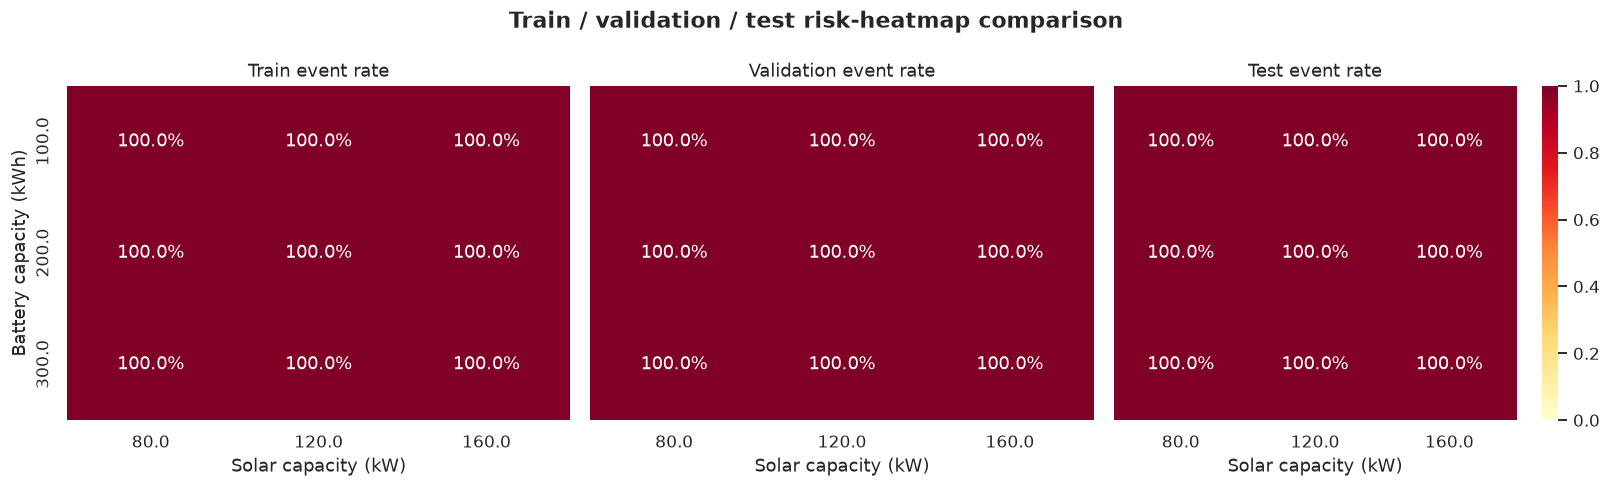

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, split_name in zip(axes, ("train", "validation", "test"), strict=True):
    summary = split_summaries[split_name]
    risk_grid = summary.pivot(
        index="battery_capacity_kwh",
        columns="solar_capacity_kw",
        values="empirical_event_rate",
    )
    sns.heatmap(
        risk_grid,
        annot=True,
        fmt=".1%",
        cmap="YlOrRd",
        vmin=0.0,
        vmax=1.0,
        cbar=split_name == "test",
        ax=ax,
    )
    ax.set(
        title=f"{split_name.title()} event rate",
        xlabel="Solar capacity (kW)",
        ylabel="Battery capacity (kWh)" if split_name == "train" else "",
    )

fig.suptitle("Train / validation / test risk-heatmap comparison", fontweight="bold")
fig.tight_layout()
save_figure(fig, "split-risk-heatmaps.svg")
plt.show()


### 5.2 Inspect one sampled autonomy episode

The middle equipment configuration and sample zero are used only as a diagnostic trace. The panels show the sampled power balance, controller request versus realized battery action, post-step battery state of charge, and accumulated unmet energy.


In [22]:
trace_configuration_id = (
    f"{battery_options[1].option_id}__{solar_options[1].option_id}"
)
trace_row = split_frames["test"].loc[
    (split_frames["test"]["configuration_id"] == trace_configuration_id)
    & (split_frames["test"]["sample_id"] == 0)
].iloc[0]

def trace_values(prefix):
    """Extract one horizon-length series from a planning-study row."""
    return [
        float(trace_row[f"{prefix}_{step}"])
        for step in range(HORIZON_STEPS)
    ]

trace_hours = list(range(HORIZON_STEPS))
unmet_energy_by_step = [
    unmet_kw * TIMESTEP_HOURS
    for unmet_kw in trace_values("unmet_load")
]
cumulative_unmet_energy = pd.Series(unmet_energy_by_step).cumsum()


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/sample-autonomy-episode.svg


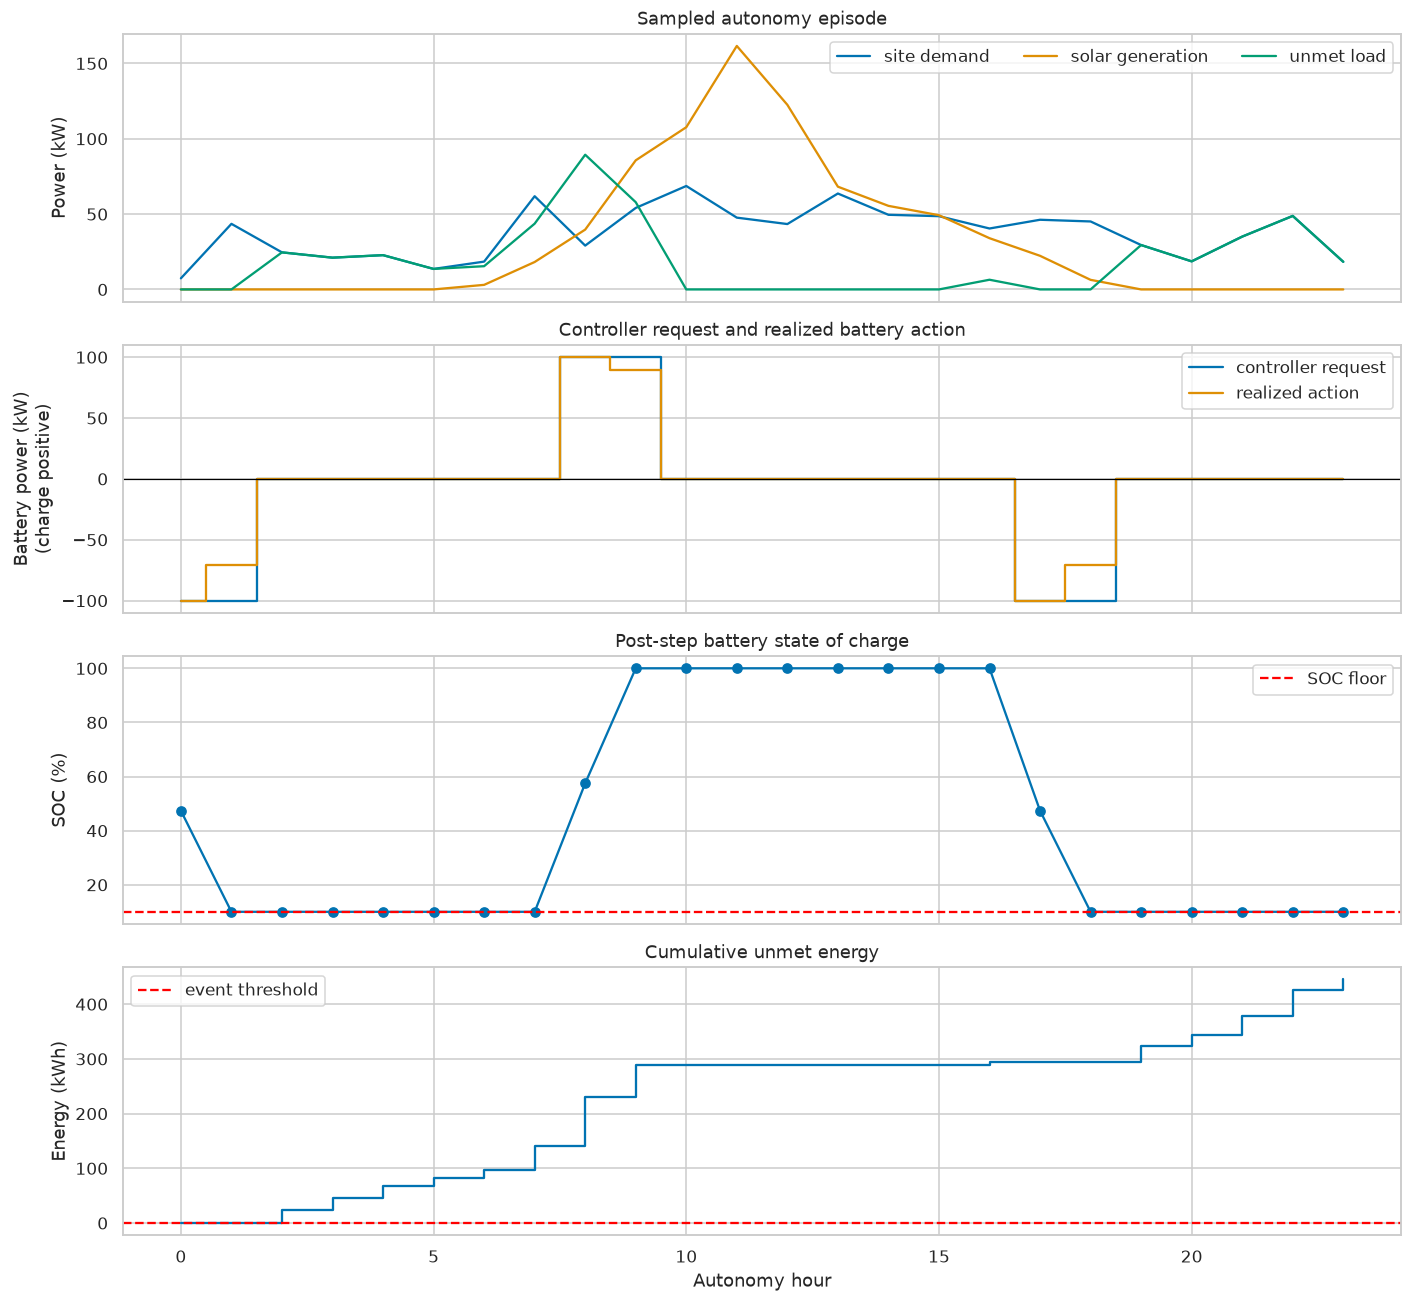

Episode unmet energy: 445.065 kWh


In [23]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)

axes[0].plot(trace_hours, trace_values("load"), label="site demand")
axes[0].plot(trace_hours, trace_values("pv_generation"), label="solar generation")
axes[0].plot(trace_hours, trace_values("unmet_load"), label="unmet load")
axes[0].set(title="Sampled autonomy episode", ylabel="Power (kW)")
axes[0].legend(ncols=3)

axes[1].step(
    trace_hours,
    trace_values("controller_request"),
    where="mid",
    label="controller request",
)
axes[1].step(
    trace_hours,
    trace_values("battery_power"),
    where="mid",
    label="realized action",
)
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set(
    title="Controller request and realized battery action",
    ylabel="Battery power (kW)\n(charge positive)",
)
axes[1].legend()

axes[2].plot(
    trace_hours,
    [100.0 * value for value in trace_values("battery_soc")],
    marker="o",
)
axes[2].axhline(100.0 * MINIMUM_SOC, color="red", linestyle="--", label="SOC floor")
axes[2].set(title="Post-step battery state of charge", ylabel="SOC (%)")
axes[2].legend()

axes[3].step(trace_hours, cumulative_unmet_energy, where="post")
axes[3].axhline(EVENT_THRESHOLD, color="red", linestyle="--", label="event threshold")
axes[3].set(
    title="Cumulative unmet energy",
    xlabel="Autonomy hour",
    ylabel="Energy (kWh)",
)
axes[3].legend()

fig.tight_layout()
save_figure(fig, "sample-autonomy-episode.svg")
plt.show()

print(f"Episode unmet energy: {trace_row['unmet_energy_kwh']:.3f} kWh")


## 6. Fit, compile, and select SPFlow candidates

Each candidate is fit only on training rows, compiled through the supported current-SPFlow-to-MIO path, and scored on validation rows. Non-compilable candidates remain visible but cannot be selected.

The candidate with the lowest validation Brier score wins. Exact ties use the smaller SPN module count. The final-test split is not consulted here.


In [24]:
def configuration_probabilities(artifact, frame):
    """Query one native SPFlow event probability per equipment configuration."""
    configurations = frame[
        ["configuration_id", "battery_option_id", "solar_option_id"]
    ].drop_duplicates()
    probabilities = {}

    for row in configurations.itertuples(index=False):
        query = TPMQueryRequest(
            decision_assignments={
                "battery_option_id": row.battery_option_id,
                "solar_option_id": row.solar_option_id,
            },
            output_mode="conditional_probability",
            target_threshold=EVENT_THRESHOLD,
            execution_mode="production",
        )
        result = query_tpm_artifact(artifact, query)
        probabilities[row.configuration_id] = float(result["value"])

    return probabilities

validation_rows = tuple(iter_study_rows(manifests["validation"]))


In [25]:
candidate_scores = []
candidate_artifacts = {}
candidate_failures = {}

for candidate_name, structure_settings in SPN_CANDIDATES.items():
    artifact_path = (
        OUTPUT_ROOT / "spn-candidates" / candidate_name / "artifact.json"
    )
    artifact_path.parent.mkdir(parents=True, exist_ok=True)

    try:
        # Fit only the training manifest with this candidate's structure settings.
        fitted = fit_planning_study_tpm(
            manifests["train"],
            output_path=artifact_path,
            max_tensor_bytes=MAX_TENSOR_BYTES,
            fit_config=TPMFitConfig(
                training_random_seed=SPLIT_SEEDS["train"],
                spn_payload_format="spflow-model-sidecar",
                learn_mspn_kwargs=structure_settings,
                notes=(f"candidate:{candidate_name}",),
            ),
        )

        # Compilation is part of candidacy: an untranslatable SPN cannot win.
        compiled = compile_planning_study_tpm(
            fitted,
            output_path=artifact_path,
        )
        validation_probabilities = configuration_probabilities(
            compiled.artifact,
            split_frames["validation"],
        )
        validation_brier = brier_score_by_configuration(
            validation_rows,
            probabilities=validation_probabilities,
            event_target_name=event_target_name,
        )
        node_count = int(
            fitted.fit_configuration["fit_summary"]["structure"]["module_count"]
        )

        score = SPNCandidateScore(
            candidate_name=candidate_name,
            validation_brier_score=validation_brier,
            node_count=node_count,
            compilable=True,
        )
        candidate_artifacts[candidate_name] = compiled

    except Exception as exc:
        # Preserve the failure so selection remains transparent.
        failure = f"{type(exc).__name__}: {exc}"
        candidate_failures[candidate_name] = failure
        score = SPNCandidateScore(
            candidate_name=candidate_name,
            validation_brier_score=1.0,
            node_count=10**9,
            compilable=False,
            failure_reason=failure,
        )

    candidate_scores.append(score)


used 3 iterations (0.0041s) to cluster 9000 items into 2 clusters
used 3 iterations (0.003s) to cluster 6000 items into 2 clusters
used 3 iterations (0.002s) to cluster 3000 items into 2 clusters
used 3 iterations (0.004s) to cluster 9000 items into 2 clusters
used 3 iterations (0.0031s) to cluster 6000 items into 2 clusters
used 3 iterations (0.0021s) to cluster 3000 items into 2 clusters
used 3 iterations (0.0036s) to cluster 9000 items into 2 clusters
used 2 iterations (0.0019s) to cluster 4001 items into 2 clusters
used 2 iterations (0.0019s) to cluster 3001 items into 2 clusters
used 4 iterations (0.0024s) to cluster 2000 items into 2 clusters
used 3 iterations (0.002s) to cluster 1000 items into 2 clusters
used 3 iterations (0.002s) to cluster 4999 items into 2 clusters
used 2 iterations (0.001s) to cluster 2000 items into 2 clusters
used 3 iterations (0.0019s) to cluster 1000 items into 2 clusters
used 3 iterations (0.002s) to cluster 1000 items into 2 clusters
used 3 iterations

In [26]:
candidate_frame = pd.DataFrame(
    [
        {
            "candidate": score.candidate_name,
            "compilable": score.compilable,
            "validation_brier": score.validation_brier_score,
            "node_count": score.node_count,
            "failure": score.failure_reason,
        }
        for score in candidate_scores
    ]
)
display(candidate_frame)

selected_candidate_score = select_spn_candidate(candidate_scores)
selected_candidate = candidate_artifacts[selected_candidate_score.candidate_name]

print("Selected candidate:", selected_candidate_score.candidate_name)
print("Compiled MIO nodes:", len(selected_candidate.compiled_payload["nodes"]))


,candidate,compilable,validation_brier,node_count,failure
0,default,False,1.000000e+00,1000000000,RuntimeError: max(): Expected reduction dim to...
1,finer,False,1.000000e+00,1000000000,RuntimeError: max(): Expected reduction dim to...
2,coarser,True,1.234568e-08,120,NaN


Selected candidate: coarser
Compiled MIO nodes: 64


## 7. Solve with HiGHS and verify native/MIO parity

The solve always runs, even if later calibration blocks a recommendation. The encoded chance constraint uses the configured event threshold and epsilon.

An encoded/native discrepancy over `1e-6`, or a native probability over epsilon, changes an otherwise optimal workflow result to validation failure.


In [27]:
solution = solve_planning_study(
    selected_candidate.artifact,
    manifests["train"],
    chance_limit_epsilon=CHANCE_LIMIT,
    validation_tolerance=NATIVE_MIO_TOLERANCE,
)

solve_overview = {
    "workflow status": solution.status,
    "selected design": dict(solution.solve_summary.selected_design),
    "installed cost AED": solution.solve_summary.objective_value,
    "encoded probability": solution.solve_summary.estimated_shortfall_risk,
    "native probability": solution.native_event_probability,
    "native/MIO discrepancy": solution.probability_discrepancy,
}
display(pd.Series(solve_overview, name="planning solve"))

# Keep the complete backend provenance visible for reproducibility.
display(pd.Series(solution.solve_summary.solver_metadata, name="HiGHS metadata"))


workflow status           infeasible
selected design                   {}
installed cost AED              None
encoded probability             None
native probability              None
native/MIO discrepancy          None
Name: planning solve, dtype: object

canonical_backend                                                        pyomo
solver_backend_required                                                   True
solver_execution_optional                                                False
solver_name                                                              highs
dataset_fixture_path                                                      None
training_random_seed                                                        13
fit_numeric_tolerance                                                      0.0
query_numeric_tolerance                                                    0.0
approximation_kind                                                   piecewise
solver_numeric_tolerance                                                   0.0
solver_random_seed                                                          13
solver_threads                                                               1
time_limit_seconds                                  

## 8. Apply the final held-out calibration and recommendation gate

Final calibration requires mean configuration error no greater than 5 percentage points, maximum error no greater than 10 points, both event labels in the final-test set, and the selected design's native probability inside its two-sided 95% held-out interval.

Recommendation additionally requires native/MIO agreement and a one-sided held-out 95% risk upper bound no greater than 5%. The final-test split is used here for the first time.


In [28]:
test_rows = tuple(iter_study_rows(manifests["test"]))
test_probabilities = configuration_probabilities(
    selected_candidate.artifact,
    split_frames["test"],
)

if solution.solve_summary.selected_design:
    selected_configuration_id = (
        f"{solution.solve_summary.selected_design['battery_option_id']}__"
        f"{solution.solve_summary.selected_design['solar_option_id']}"
    )
else:
    # This fallback supports calibration diagnostics only; it is not a recommendation.
    selected_configuration_id = (
        split_summaries["test"]
        .sort_values("installed_cost")
        .iloc[0]["configuration_id"]
    )
    print(
        "No optimizer design was available; the cheapest configuration is "
        "used only for calibration diagnostics."
    )


No optimizer design was available; the cheapest configuration is used only for calibration diagnostics.


In [29]:
calibration = assess_calibration(
    test_rows,
    probabilities=test_probabilities,
    event_target_name=event_target_name,
    selected_configuration_id=selected_configuration_id,
    mean_error_limit=MEAN_CALIBRATION_ERROR_LIMIT,
    max_error_limit=MAX_CALIBRATION_ERROR_LIMIT,
)
recommendation = assess_recommendation(
    calibration=calibration,
    solve_status=solution.status,
    native_mio_discrepancy=float(
        solution.probability_discrepancy
        if solution.probability_discrepancy is not None
        else 1.0
    ),
    chance_limit=CHANCE_LIMIT,
    parity_tolerance=NATIVE_MIO_TOLERANCE,
)

calibration_frame = pd.DataFrame(
    [asdict(result) for result in calibration.configuration_results]
)
display(calibration_frame)

calibration_overview = {
    "mean configuration error": calibration.mean_configuration_error,
    "maximum configuration error": calibration.maximum_configuration_error,
    "both labels observed": calibration.both_labels_observed,
    "selected probability inside CI": (
        calibration.selected_probability_in_confidence_interval
    ),
    "one-sided 95% upper risk bound": recommendation.one_sided_upper_risk_bound,
}
display(pd.Series(calibration_overview, name="held-out assessment"))


,configuration_id,predicted_probability,empirical_probability,event_count,sample_count,confidence_interval_lower,confidence_interval_upper,absolute_error
0,battery-100__solar-120,0.999889,1.0,250,250,0.984867,1.0,0.000111
1,battery-100__solar-160,0.999889,1.0,250,250,0.984867,1.0,0.000111
2,battery-100__solar-80,0.999889,1.0,250,250,0.984867,1.0,0.000111
3,battery-200__solar-120,0.999889,1.0,250,250,0.984867,1.0,0.000111
4,battery-200__solar-160,0.999889,1.0,250,250,0.984867,1.0,0.000111
5,battery-200__solar-80,0.999889,1.0,250,250,0.984867,1.0,0.000111
6,battery-300__solar-120,0.999889,1.0,250,250,0.984867,1.0,0.000111
7,battery-300__solar-160,0.999889,1.0,250,250,0.984867,1.0,0.000111
8,battery-300__solar-80,0.999889,1.0,250,250,0.984867,1.0,0.000111


mean configuration error          0.000111
maximum configuration error       0.000111
both labels observed                 False
selected probability inside CI        True
one-sided 95% upper risk bound         1.0
Name: held-out assessment, dtype: object

### 8.1 Compare native SPFlow probabilities with held-out evidence

Points show the final-test empirical event rate and its two-sided 95% confidence interval. Crosses show the native SPFlow probability for the same equipment configuration.


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/spn-versus-heldout-probability.svg


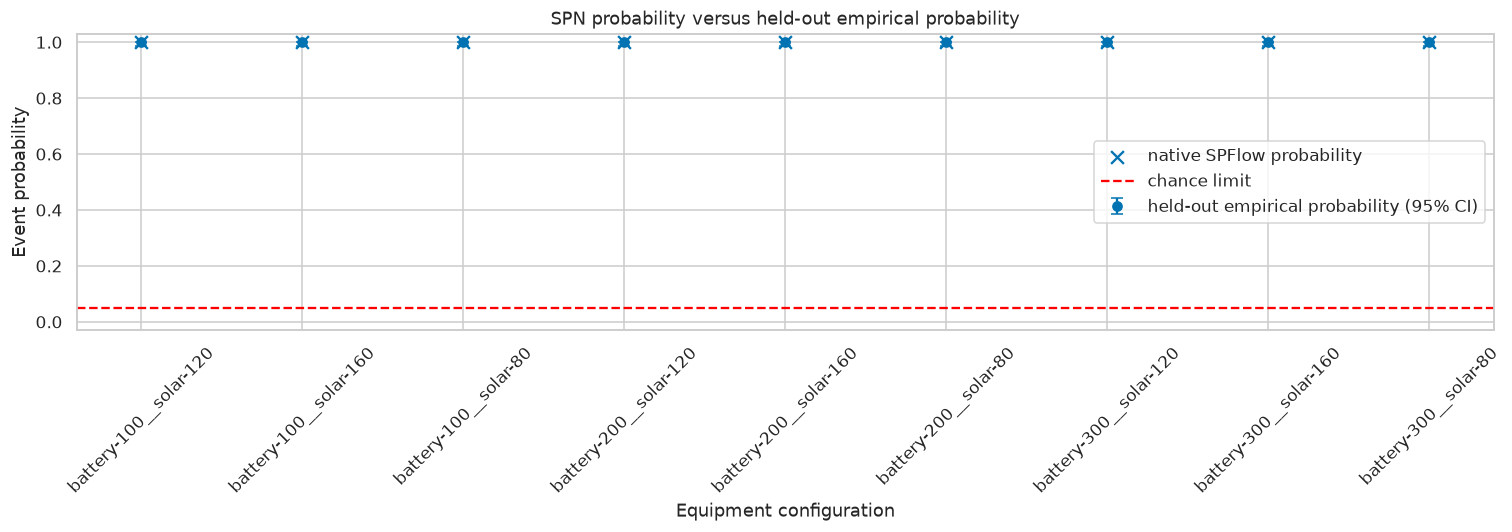

In [30]:
ordered_calibration = calibration_frame.sort_values("configuration_id").reset_index(drop=True)
x_positions = list(range(len(ordered_calibration)))

empirical = ordered_calibration["empirical_probability"]
# Error-bar distances can acquire tiny negative round-off at exact 0/1 bounds.
lower_error = (
    empirical - ordered_calibration["confidence_interval_lower"]
).clip(lower=0.0)
upper_error = (
    ordered_calibration["confidence_interval_upper"] - empirical
).clip(lower=0.0)

fig, ax = plt.subplots(figsize=(14, 5))
ax.errorbar(
    x_positions,
    empirical,
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=4,
    label="held-out empirical probability (95% CI)",
)
ax.scatter(
    x_positions,
    ordered_calibration["predicted_probability"],
    marker="x",
    s=70,
    label="native SPFlow probability",
)
ax.axhline(CHANCE_LIMIT, color="red", linestyle="--", label="chance limit")
ax.set(
    title="SPN probability versus held-out empirical probability",
    xlabel="Equipment configuration",
    ylabel="Event probability",
    xticks=x_positions,
    xticklabels=ordered_calibration["configuration_id"],
    ylim=(-0.03, 1.03),
)
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
save_figure(fig, "spn-versus-heldout-probability.svg")
plt.show()


### 8.2 Inspect the cost-risk frontier

The frontier combines illustrative installed cost with native SPFlow risk. Color identifies battery capacity and marker shape identifies solar capacity; the horizontal line is the configured chance limit.


Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/cost-risk-frontier.svg


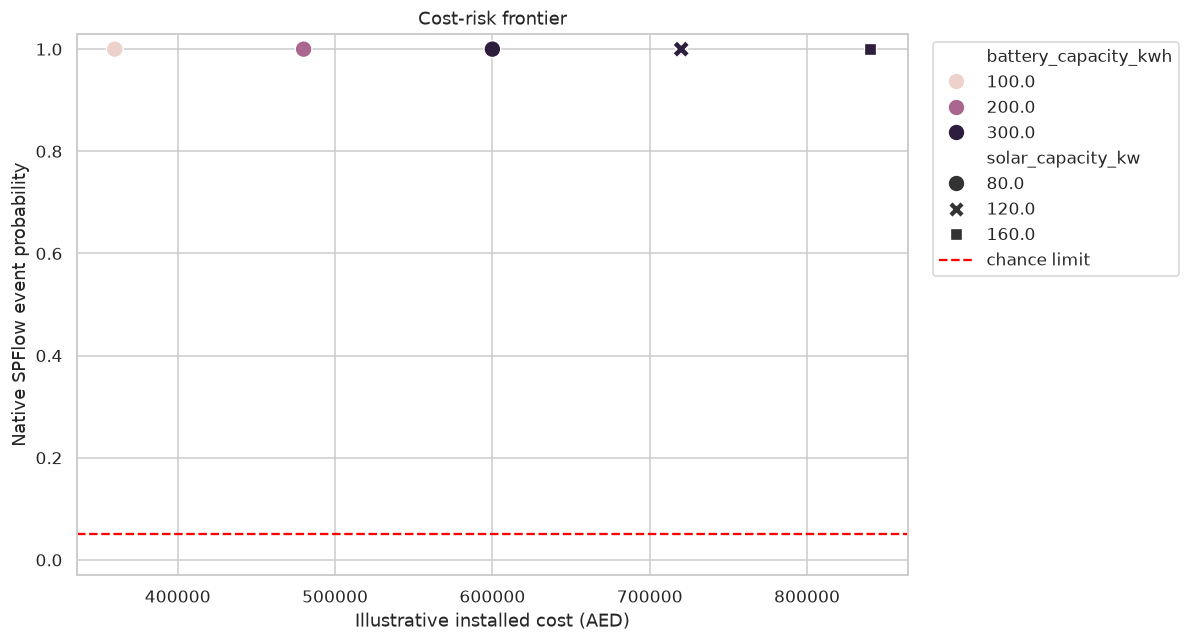

In [31]:
frontier = (
    split_summaries["test"]
    .merge(
        ordered_calibration[["configuration_id", "predicted_probability"]],
        on="configuration_id",
    )
    .sort_values("installed_cost")
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=frontier,
    x="installed_cost",
    y="predicted_probability",
    hue="battery_capacity_kwh",
    style="solar_capacity_kw",
    s=120,
    ax=ax,
)
ax.axhline(CHANCE_LIMIT, color="red", linestyle="--", label="chance limit")
ax.set(
    title="Cost-risk frontier",
    xlabel="Illustrative installed cost (AED)",
    ylabel="Native SPFlow event probability",
    ylim=(-0.03, 1.03),
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
save_figure(fig, "cost-risk-frontier.svg")
plt.show()


## 9. Final recommendation status

The status below is generated from the same gate object used by the workflow. An optimizer design is not presented as a recommendation unless every calibration, parity, solve, and risk-bound condition passes.


status                                                                       exploratory
selected_design                                                                       {}
installed_cost_aed                                                                  None
native_event_probability                                                            None
native_mio_discrepancy                                                              None
heldout_one_sided_95pct_upper_bound                                                  1.0
blocking_reasons                       (held-out calibration gate did not pass, plann...
conditioned_on                         [location, horizon, local start hour, initial ...
Name: final study summary, dtype: object

Saved /home/nicolas.avila/dev/open-energy-lab/tmp/abu-dhabi-autonomy-study/visualizations/final-recommendation-status.svg


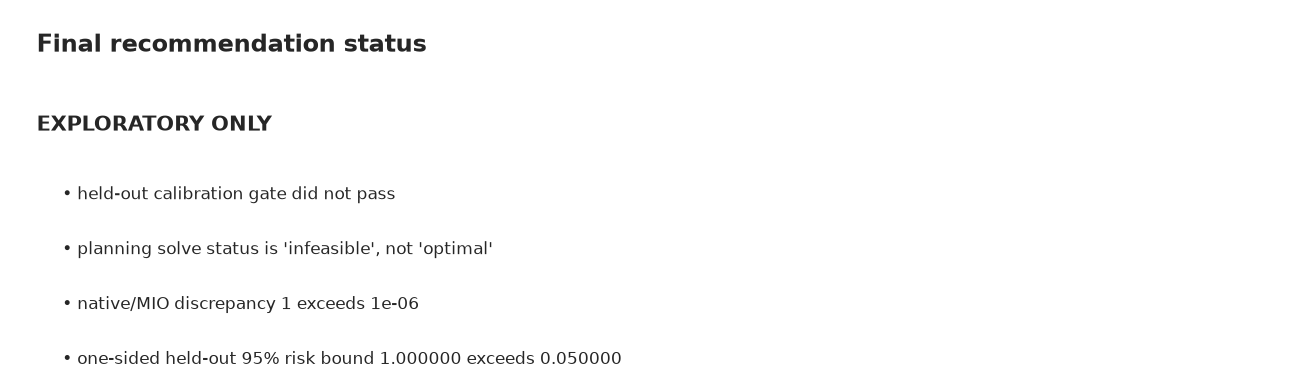

In [32]:
summary = {
    "status": recommendation.status,
    "selected_design": dict(solution.solve_summary.selected_design),
    "installed_cost_aed": solution.solve_summary.objective_value,
    "native_event_probability": solution.native_event_probability,
    "native_mio_discrepancy": solution.probability_discrepancy,
    "heldout_one_sided_95pct_upper_bound": (
        recommendation.one_sided_upper_risk_bound
    ),
    "blocking_reasons": recommendation.blocking_reasons,
    "conditioned_on": [
        "location",
        "horizon",
        "local start hour",
        "initial SOC",
        "controller",
        "demand model",
        "TMY-based uncertainty",
        "equipment grid and costs",
        "event threshold",
        "chance limit",
    ],
}
display(pd.Series(summary, name="final study summary"))

if recommendation.recommendation_allowed:
    status_title = "RECOMMENDED"
    status_color = "#d1fae5"
    status_lines = ["The selected design passed every configured evidence gate."]
else:
    status_title = "EXPLORATORY ONLY"
    status_color = "#fef3c7"
    status_lines = list(recommendation.blocking_reasons)

fig, ax = plt.subplots(figsize=(12, 1.8 + 0.45 * len(status_lines)))
ax.set_facecolor(status_color)
ax.axis("off")
ax.text(0.02, 0.88, "Final recommendation status", fontsize=16, fontweight="bold")
ax.text(0.02, 0.65, status_title, fontsize=14, fontweight="bold")

for line_index, line in enumerate(status_lines):
    ax.text(0.04, 0.45 - 0.16 * line_index, f"• {line}", fontsize=11)

fig.tight_layout()
save_figure(fig, "final-recommendation-status.svg")
plt.show()


## Conditional conclusion

Any result above is conditional on the configured location, horizon, local start hour, explicitly reset initial SOC, controller, demand model, TMY-based weather uncertainty, equipment catalog, illustrative costs, grid policy, event threshold, and chance limit. It is not an absolute blackout guarantee.

TMY does not represent interannual extremes, and the default synthetic demand is not site-calibrated. Preserve the canonical-weather cache provenance, all three manifests, each candidate artifact, compiler metadata, HiGHS metadata, and the final gate output together.
